# Partie 1 — Nettoyage et preprocessing : Indonesia Tourism

**Objectif** : transformer les 4 fichiers bruts du dataset *Indonesia Tourism Destination* en tables propres et en variables prêtes pour le moteur de recommandation (Partie 2).

**Sommaire**
1. Configuration et chargement
2. Audit des données brutes
3. Nettoyage des lieux
4. Nettoyage des notes, des utilisateurs et des circuits
5. Preprocessing (variables, matrice utilisateur-lieu, découpage train/test)
6. Sauvegarde et contrôles finaux

## 1. Configuration et chargement

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (8, 4.5)

RANDOM_STATE = 42
IDR_PER_EUR = 18_500  # taux approximatif (1 EUR en roupies) : à mettre à jour

# Le notebook fonctionne dans le dossier du projet (notebooks/) ou seul :
# si les CSV ne sont pas en local, ils sont lus depuis GitHub.
CWD = Path.cwd()
ROOT = CWD.parent if CWD.name == "notebooks" else CWD
RAW_DIR = ROOT / "data" / "raw" / "indonesia"
PROC_DIR = ROOT / "data" / "processed"
PROC_DIR.mkdir(parents=True, exist_ok=True)
GITHUB_RAW = "https://raw.githubusercontent.com/akhiyarwaladi/indonesia_tourism/main"


def read(name):
    local = RAW_DIR / name
    return pd.read_csv(local if local.exists() else f"{GITHUB_RAW}/{name}")

In [2]:
places_raw = read("tourism_with_id.csv")
ratings_raw = read("tourism_rating.csv")
users_raw = read("user.csv")
packages_raw = read("package_tourism.csv")

for name, df in {"lieux": places_raw, "notes": ratings_raw, "utilisateurs": users_raw, "circuits": packages_raw}.items():
    print(f"{name:13s} {df.shape[0]:>6} lignes x {df.shape[1]:>2} colonnes")
places_raw.head(3)

lieux            437 lignes x 13 colonnes
notes          10000 lignes x  3 colonnes
utilisateurs     300 lignes x  3 colonnes
circuits         100 lignes x  7 colonnes


,Place_Id,Place_Name,Description,Category,City,Price,Rating,Time_Minutes,Coordinate,Lat,Long,Unnamed: 11,Unnamed: 12
0,1,Monumen Nasional,Monumen Nasional atau yang populer disingkat d...,Budaya,Jakarta,20000,4.6,15.0,"{'lat': -6.1753924, 'lng': 106.8271528}",-6.175392,106.827153,NaN,1
1,2,Kota Tua,"Kota tua di Jakarta, yang juga bernama Kota Tu...",Budaya,Jakarta,0,4.6,90.0,"{'lat': -6.137644799999999, 'lng': 106.8171245}",-6.137645,106.817125,NaN,2
2,3,Dunia Fantasi,Dunia Fantasi atau disebut juga Dufan adalah t...,Taman Hiburan,Jakarta,270000,4.6,360.0,"{'lat': -6.125312399999999, 'lng': 106.8335377}",-6.125312,106.833538,NaN,3


## 2. Audit des données brutes

In [3]:
audit = pd.DataFrame({
    "type": places_raw.dtypes.astype(str),
    "manquants": places_raw.isna().sum(),
    "% manquants": (places_raw.isna().mean() * 100).round(1),
    "valeurs uniques": places_raw.nunique(),
})
audit

,type,manquants,% manquants,valeurs uniques
Place_Id,int64,0,0.0,437
Place_Name,str,0,0.0,437
Description,str,0,0.0,437
Category,str,0,0.0,6
City,str,0,0.0,5
Price,int64,0,0.0,50
Rating,float64,0,0.0,14
Time_Minutes,float64,232,53.1,15
Coordinate,str,0,0.0,437
Lat,float64,0,0.0,437


In [4]:
print("Place_Id en double       :", places_raw["Place_Id"].duplicated().sum())
print("Noms de lieux en double  :", places_raw["Place_Name"].duplicated().sum())
print("Notes en double (user, lieu):", ratings_raw.duplicated(["User_Id", "Place_Id"]).sum())
places_raw[["Price", "Rating", "Time_Minutes", "Lat", "Long"]].describe().round(2)

Place_Id en double       : 0
Noms de lieux en double  : 0
Notes en double (user, lieu): 403


,Price,Rating,Time_Minutes,Lat,Long
count,437.00,437.00,205.00,437.00,437.00
mean,24652.17,4.44,82.61,-7.10,109.16
std,66446.37,0.21,52.87,0.73,1.96
min,0.00,3.40,10.00,-8.20,103.93
25%,0.00,4.30,45.00,-7.75,107.58
50%,5000.00,4.50,60.00,-7.02,110.24
75%,20000.00,4.60,120.00,-6.83,110.43
max,900000.00,5.00,360.00,1.08,112.82


**Constats de l'audit**
- Deux colonnes parasites (`Unnamed: 11`, `Unnamed: 12`) et une colonne `Coordinate` redondante avec `Lat`/`Long`.
- `Time_Minutes` est manquante pour plus de la moitié des lieux.
- Des prix à 0 (entrée gratuite ou donnée absente) et des prix en roupies indonésiennes (IDR).
- Des notes utilisateurs en double pour un même couple utilisateur/lieu.

## 3. Nettoyage des lieux

### 3.1 Colonnes parasites, noms de colonnes et texte

In [5]:
places = (
    places_raw
    .drop(columns=[c for c in places_raw.columns if c.startswith("Unnamed") or c == "Coordinate"])
    .rename(columns={
        "Place_Id": "place_id", "Place_Name": "name", "Description": "description",
        "Category": "category_raw", "City": "city", "Price": "price_idr", "Rating": "rating",
        "Time_Minutes": "visit_minutes", "Lat": "lat", "Long": "lon",
    })
)
for col in ["name", "description", "category_raw", "city"]:
    places[col] = places[col].astype("string").str.strip()
places.columns.tolist()

['place_id',
 'name',
 'description',
 'category_raw',
 'city',
 'price_idr',
 'rating',
 'visit_minutes',
 'lat',
 'lon']

### 3.2 Catégories (indonésien → anglais)

In [6]:
CATEGORY_EN = {
    "Bahari": "sea",                  # mer, plages, îles
    "Budaya": "culture",              # culture, musées, monuments
    "Cagar Alam": "nature",           # réserves naturelles
    "Pusat Perbelanjaan": "shopping", # centres commerciaux
    "Taman Hiburan": "amusement",     # parcs de loisirs
    "Tempat Ibadah": "religious",     # lieux de culte
}
unknown = set(places["category_raw"]) - set(CATEGORY_EN)
print("Catégories inconnues :", unknown or "aucune")
places["category"] = places["category_raw"].map(CATEGORY_EN)
places["category"].value_counts()

Catégories inconnues : aucune


category
amusement    135
culture      117
nature       106
sea           47
religious     17
shopping      15
Name: count, dtype: int64

### 3.3 Durée de visite (`visit_minutes`) : valeurs manquantes
Plus de la moitié des durées manquent. On impute par la **médiane de la catégorie** (les durées de visite d'un même type de lieu se ressemblent), et on garde un **indicateur** pour ne pas perdre l'information.

In [7]:
duree = places.groupby("category").agg(
    lieux=("place_id", "size"),
    durees_observees=("visit_minutes", "count"),
    mediane_min=("visit_minutes", "median"),
)
duree["% manquant"] = ((1 - duree["durees_observees"] / duree["lieux"]) * 100).round(0)
duree

,lieux,durees_observees,mediane_min,% manquant
category,,,,
amusement,135,72,60.0,47.0
culture,117,61,60.0,48.0
nature,106,54,90.0,49.0
religious,17,0,NaN,100.0
sea,47,8,90.0,83.0
shopping,15,10,60.0,33.0


In [8]:
# La catégorie "religious" n'a aucune durée observée : on retombe sur la médiane globale.
places["visit_minutes_imputed"] = places["visit_minutes"].isna()
cat_median = places.groupby("category")["visit_minutes"].transform("median")
global_median = places["visit_minutes"].median()
places["visit_minutes"] = places["visit_minutes"].fillna(cat_median).fillna(global_median).astype(int)

print("Durée médiane globale :", global_median, "min")
print("Lieux imputés :", places["visit_minutes_imputed"].sum(), f"({places['visit_minutes_imputed'].mean():.0%})")
print("Valeurs manquantes restantes :", places["visit_minutes"].isna().sum())

Durée médiane globale : 60.0 min
Lieux imputés : 232 (53%)
Valeurs manquantes restantes : 0


### 3.4 Prix : gratuité, conversion en euros, tranches

In [9]:
print("Lieux à prix 0 :", (places["price_idr"] == 0).sum(), f"({(places['price_idr'] == 0).mean():.0%})")
places.loc[places["price_idr"] > 0, "price_idr"].describe().round(0)

Lieux à prix 0 : 137 (31%)


count       300.0
mean      35910.0
std       77669.0
min        1000.0
25%        5000.0
50%       10000.0
75%       30000.0
max      900000.0
Name: price_idr, dtype: float64

In [10]:
places["is_free"] = places["price_idr"] == 0
places["price_eur"] = (places["price_idr"] / IDR_PER_EUR).round(2)

# Trois tranches de même effectif parmi les lieux payants.
places["price_tier"] = "free"
paid = places.loc[~places["is_free"], "price_idr"]
places.loc[~places["is_free"], "price_tier"] = pd.qcut(
    paid.rank(method="first"), 3, labels=["low", "medium", "high"]
).astype(str)

places.groupby("price_tier")["price_idr"].agg(["count", "min", "max"])

,count,min,max
price_tier,,,
free,137,0,0
high,100,20000,900000
low,100,1000,7000
medium,100,7500,20000


In [11]:
# Les lieux les plus chers : à vérifier qu'il s'agit de vrais prix et non d'erreurs
places.nlargest(5, "price_idr")[["name", "city", "category", "price_idr", "price_eur"]]

,name,city,category,price_idr,price_eur
13,Pulau Pelangi,Jakarta,sea,900000,48.65
143,Goa Jomblang,Yogyakarta,nature,500000,27.03
296,Mountain View Golf Club,Bandung,nature,375000,20.27
71,Waterboom PIK (Pantai Indah Kapuk),Jakarta,amusement,300000,16.22
213,Trans Studio Bandung,Bandung,amusement,280000,15.14


### 3.5 Coordonnées et note moyenne du lieu

In [12]:
BBOX = {"lat": (-11.5, 6.5), "lon": (94.5, 141.5)}  # rectangle englobant l'Indonésie
places["coords_ok"] = places["lat"].between(*BBOX["lat"]) & places["lon"].between(*BBOX["lon"])
print("Coordonnées hors Indonésie :", (~places["coords_ok"]).sum())
print("Note moyenne des lieux (colonne rating) : min", places["rating"].min(), "/ max", places["rating"].max())

Coordonnées hors Indonésie : 0
Note moyenne des lieux (colonne rating) : min 3.4 / max 5.0


Le rectangle englobant ne détecte que les erreurs grossières. On vérifie aussi la **cohérence avec la ville** : distance entre chaque lieu et le centre médian de sa ville. Beaucoup de lieux éloignés sont légitimes (îles au large de Jakarta, plages de Gunungkidul), mais au-delà de 100 km c'est très probablement une erreur de saisie.

In [13]:
def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


med = places.groupby("city")[["lat", "lon"]].transform("median")
places["dist_to_city_median_km"] = haversine_km(places["lat"], places["lon"], med["lat"], med["lon"]).round(1)
SUSPECT_KM = 100
places["coords_suspect"] = places["dist_to_city_median_km"] > SUSPECT_KM

print(f"Lieux à plus de 50 km du centre de leur ville : {(places['dist_to_city_median_km'] > 50).sum()} (souvent légitimes : îles, plages)")
print(f"Lieux suspects (> {SUSPECT_KM} km) : {places['coords_suspect'].sum()} -> signalés, pas supprimés")
places.loc[places["coords_suspect"], ["place_id", "name", "city", "lat", "lon", "dist_to_city_median_km"]]

Lieux à plus de 50 km du centre de leur ville : 11 (souvent légitimes : îles, plages)
Lieux suspects (> 100 km) : 2 -> signalés, pas supprimés


,place_id,name,city,lat,lon,dist_to_city_median_km
8,9,Pelabuhan Marina,Jakarta,1.078880,103.931398,868.7
322,323,Kebun Tanaman Obat Sari Alam,Bandung,-6.601321,106.632734,112.7


### 3.6 Visualisation des lieux nettoyés

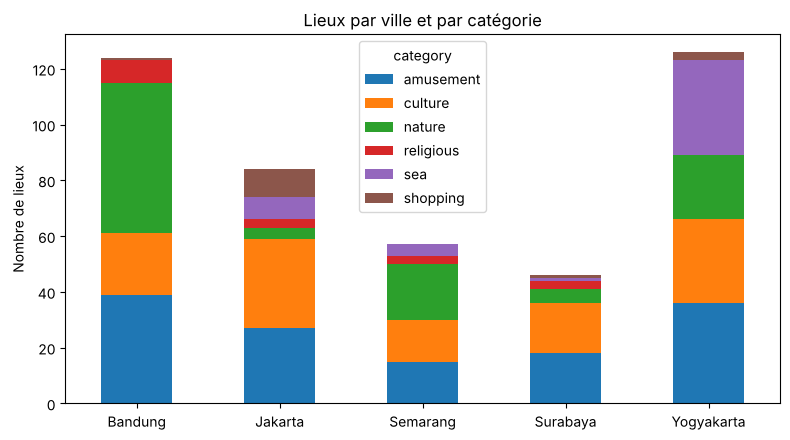

category,amusement,culture,nature,religious,sea,shopping
city,,,,,,
Bandung,39,22,54,8,0,1
Jakarta,27,32,4,3,8,10
Semarang,15,15,20,3,4,0
Surabaya,18,18,5,3,1,1
Yogyakarta,36,30,23,0,34,3


In [14]:
ct = places.groupby(["city", "category"]).size().unstack(fill_value=0)
ax = ct.plot(kind="bar", stacked=True)
ax.set_title("Lieux par ville et par catégorie")
ax.set_xlabel("")
ax.set_ylabel("Nombre de lieux")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
ct

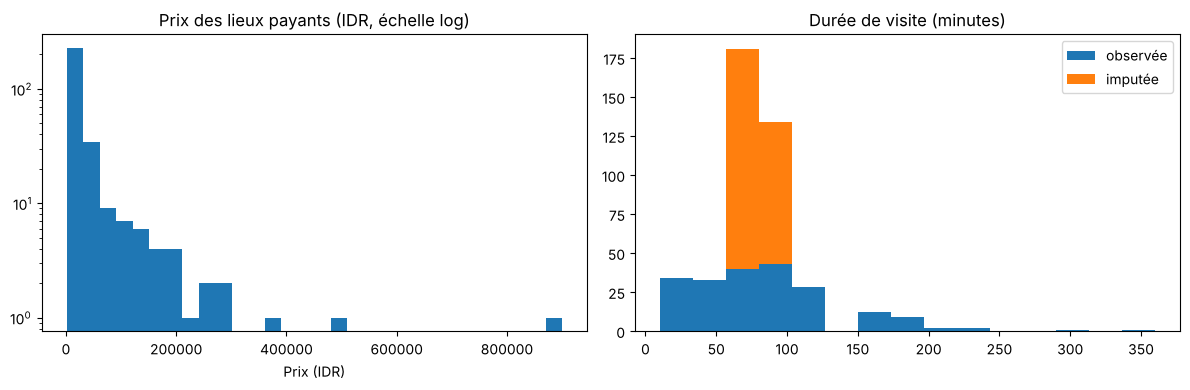

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(places.loc[~places["is_free"], "price_idr"], bins=30, log=True)
axes[0].set_title("Prix des lieux payants (IDR, échelle log)")
axes[0].set_xlabel("Prix (IDR)")
obs = places.loc[~places["visit_minutes_imputed"], "visit_minutes"]
imp = places.loc[places["visit_minutes_imputed"], "visit_minutes"]
axes[1].hist([obs, imp], bins=15, stacked=True, label=["observée", "imputée"])
axes[1].set_title("Durée de visite (minutes)")
axes[1].legend()
plt.tight_layout()
plt.show()

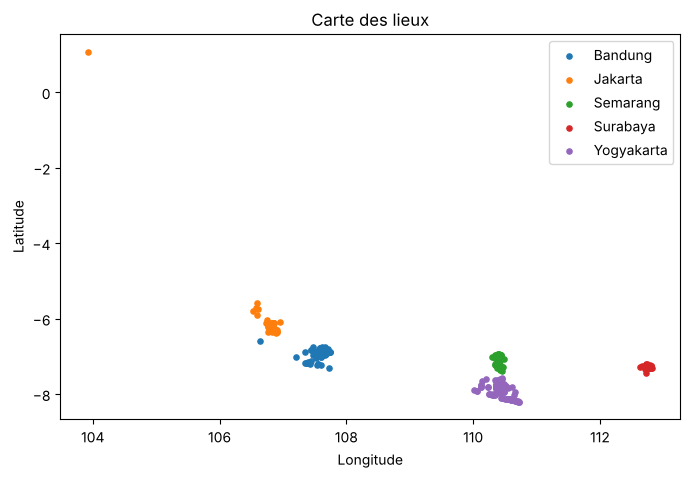

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
for city, g in places.groupby("city"):
    ax.scatter(g["lon"], g["lat"], s=14, label=city)
ax.set_title("Carte des lieux")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()
plt.show()

## 4. Nettoyage des notes, des utilisateurs et des circuits

### 4.1 Notes utilisateurs

In [17]:
ratings = ratings_raw.rename(columns={"User_Id": "user_id", "Place_Id": "place_id", "Place_Ratings": "user_rating"})

orphans = (~ratings["place_id"].isin(places["place_id"])).sum()
dups = ratings.duplicated(["user_id", "place_id"]).sum()
print("Notes sur un lieu inconnu :", orphans)
print("Notes en double (même utilisateur, même lieu) :", dups)

ratings = ratings[ratings["place_id"].isin(places["place_id"])]
# Un utilisateur qui a noté deux fois le même lieu : on garde la moyenne
ratings = ratings.groupby(["user_id", "place_id"], as_index=False)["user_rating"].mean()
print("Notes après nettoyage :", len(ratings), "(avant :", len(ratings_raw), ")")

Notes sur un lieu inconnu : 0
Notes en double (même utilisateur, même lieu) : 403
Notes après nettoyage : 9597 (avant : 10000 )


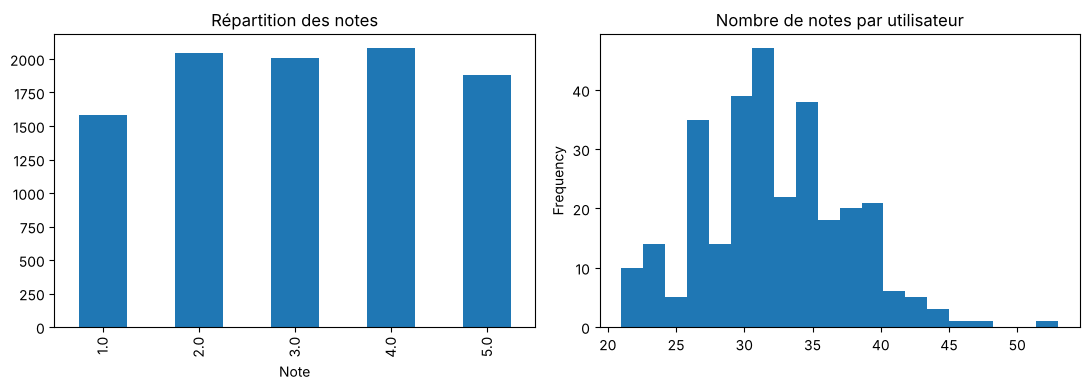

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ratings["user_rating"].round().value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Répartition des notes")
axes[0].set_xlabel("Note")
ratings.groupby("user_id").size().plot(kind="hist", bins=20, ax=axes[1])
axes[1].set_title("Nombre de notes par utilisateur")
plt.tight_layout()
plt.show()

La répartition des notes est **presque uniforme** entre 1 et 5 : le signal est faible, ce qui est à garder en tête pour le filtrage collaboratif (Partie 2).

### 4.2 Utilisateurs

In [19]:
users = users_raw.rename(columns={"User_Id": "user_id", "Location": "location", "Age": "age"})
parts = users["location"].str.split(",", n=1, expand=True)
users["origin_city"] = parts[0].str.strip()
users["origin_province"] = parts[1].str.strip()

print("Âge min/max :", users["age"].min(), "/", users["age"].max())
print("Valeurs manquantes :", users.isna().sum().sum())
users.head()

Âge min/max : 18 / 40
Valeurs manquantes : 0


,user_id,location,age,origin_city,origin_province
0,1,"Semarang, Jawa Tengah",20,Semarang,Jawa Tengah
1,2,"Bekasi, Jawa Barat",21,Bekasi,Jawa Barat
2,3,"Cirebon, Jawa Barat",23,Cirebon,Jawa Barat
3,4,"Bekasi, Jawa Barat",21,Bekasi,Jawa Barat
4,5,"Lampung, Sumatera Selatan",20,Lampung,Sumatera Selatan


### 4.3 Circuits touristiques
Chaque circuit contient 5 lieux désignés **par leur nom** (pas par leur identifiant). On passe au format long et on rapproche chaque nom d'un `place_id`. Quelques noms diffèrent légèrement de ceux de la table des lieux (préfixe « | », variantes de nom) : on les corrige.

In [20]:
packages = packages_raw.rename(columns={"Package": "package_id", "City": "city"}).melt(
    id_vars=["package_id", "city"],
    value_vars=[c for c in packages_raw.columns if c.startswith("Place_Tourism")],
    var_name="position", value_name="place_name",
)
packages["position"] = packages["position"].str.extract(r"(\d+)").astype(int)
packages = packages.dropna(subset=["place_name"]).copy()

# Préfixes "| " parasites en début de nom
packages["place_name"] = packages["place_name"].str.strip().str.replace(r"^\|\s*", "", regex=True).str.strip()

key = places[["place_id", "name", "city"]].rename(columns={"name": "place_name"})
first_try = packages.merge(key, on=["place_name", "city"], how="left")
print("Noms non rapprochés avant correction :", first_try["place_id"].isna().sum())
first_try.loc[first_try["place_id"].isna(), ["package_id", "city", "place_name"]]

Noms non rapprochés avant correction : 8


,package_id,city,place_name
41,42,Bandung,Gunung Tangkuban Perahu
102,3,Jakarta,Monas
130,31,Yogyakarta,Taman Pelangi Jogja
207,8,Jakarta,Monas
267,68,Semarang,Semarang Gallery
376,32,Yogyakarta,Wisata Kalibiru
384,52,Bandung,Stone Garden Geopark
385,53,Bandung,Ade Irma Suryani Nasution Traffic Park


In [21]:
# Correspondances manuelles. Les deux dernières sont plausibles mais à valider.
PLACE_ALIASES = {
    "Monas": "Monumen Nasional",
    "Taman Pelangi Jogja": "Taman Pelangi Yogyakarta",
    "Wisata Kalibiru": "Wisata Alam Kalibiru",
    "Gunung Tangkuban Perahu": "GunungTangkuban perahu",
    "Ade Irma Suryani Nasution Traffic Park": "Taman Lalu Lintas Ade Irma Suryani Nasution",
    "Stone Garden Geopark": "Stone Garden Citatah",       # à valider
    "Semarang Gallery": "Semarang Contemporary Art Gallery",  # à valider
}
packages["place_name"] = packages["place_name"].replace(PLACE_ALIASES)
packages = packages.merge(key, on=["place_name", "city"], how="left")
packages["place_id"] = packages["place_id"].astype("Int64")
packages = packages.sort_values(["package_id", "position"]).reset_index(drop=True)

print("Noms non rapprochés après correction :", packages["place_id"].isna().sum(), "/", len(packages))
packages.head(6)

Noms non rapprochés après correction : 0 / 405


,package_id,city,position,place_name,place_id
0,1,Jakarta,1,Pasar Tanah Abang,25
1,1,Jakarta,2,Taman Ayodya,58
2,1,Jakarta,3,Museum Tekstil,60
3,2,Jakarta,1,Pasar Tanah Abang,25
4,2,Jakarta,2,Pasar Taman Puring,34
5,2,Jakarta,3,Pasar Petak Sembilan,68


## 5. Preprocessing pour le moteur de recommandation

### 5.1 Variables dérivées des notes
On résume les notes utilisateurs par lieu (nombre et moyenne), puis on compare avec la colonne `rating` déjà présente dans la table des lieux.

In [22]:
agg = ratings.groupby("place_id")["user_rating"].agg(n_ratings="count", avg_user_rating="mean").reset_index()
agg["avg_user_rating"] = agg["avg_user_rating"].round(2)

features = places.merge(agg, on="place_id", how="left")
print("Lieux sans aucune note :", features["n_ratings"].isna().sum())
print("Corrélation entre rating (fichier lieux) et moyenne des notes utilisateurs :",
      round(features["rating"].corr(features["avg_user_rating"]), 3))
features[["name", "rating", "n_ratings", "avg_user_rating"]].head()

Lieux sans aucune note : 0
Corrélation entre rating (fichier lieux) et moyenne des notes utilisateurs : 0.008


,name,rating,n_ratings,avg_user_rating
0,Monumen Nasional,4.6,18,3.72
1,Kota Tua,4.6,24,2.85
2,Dunia Fantasi,4.6,18,2.42
3,Taman Mini Indonesia Indah (TMII),4.5,21,2.86
4,Atlantis Water Adventure,4.5,23,3.48


Une corrélation proche de 0 signifie que les notes utilisateurs ne reproduisent pas la note affichée du lieu : on ne peut pas se fier à une seule de ces deux sources pour juger la qualité d'un lieu.

### 5.2 Normalisation et encodage
- Prix : transformation `log1p` (distribution très étalée), puis mise à l'échelle entre 0 et 1.
- Durée de visite : mise à l'échelle entre 0 et 1.
- Catégorie et ville : encodage one-hot.
- Texte : un champ unique (nom, catégorie, ville, description) pour les futurs embeddings.

In [23]:
def minmax(s):
    return (s - s.min()) / (s.max() - s.min())

features["price_norm"] = minmax(np.log1p(features["price_idr"]))
features["visit_norm"] = minmax(features["visit_minutes"])

cat_dummies = pd.get_dummies(features["category"], prefix="cat").astype(int)
city_dummies = pd.get_dummies(features["city"], prefix="city").astype(int)
features = pd.concat([features, cat_dummies, city_dummies], axis=1)

# Les descriptions sont en indonésien : prévoir un modèle d'embeddings multilingue.
features["description_len"] = features["description"].str.len()
features["text_for_embedding"] = (
    features["name"] + ". " + features["category"] + ". " + features["city"] + ". " + features["description"]
)

features[["name", "price_idr", "price_norm", "visit_minutes", "visit_norm"]].describe().round(2)

,price_idr,price_norm,visit_minutes,visit_norm
count,437.00,437.00,437.00,437.00
mean,24652.17,0.48,76.85,0.19
std,66446.37,0.33,38.10,0.11
min,0.00,0.00,10.00,0.00
25%,0.00,0.00,60.00,0.14
50%,5000.00,0.62,60.00,0.14
75%,20000.00,0.72,90.00,0.23
max,900000.00,1.00,360.00,1.00


### 5.3 Matrice utilisateur × lieu

In [24]:
matrix = ratings.pivot(index="user_id", columns="place_id", values="user_rating")
sparsity = 1 - matrix.notna().sum().sum() / matrix.size
print("Dimensions :", matrix.shape)
print(f"Taux de cases vides : {sparsity:.1%}")

Dimensions : (300, 437)
Taux de cases vides : 92.7%


Environ 93 % de la matrice est vide : c'est normal pour ce type de données, et suffisant pour tester un filtrage collaboratif simple, sans être confortable.

### 5.4 Découpage train / test des notes
Pour évaluer le moteur honnêtement, on **met de côté 20 % des notes de chaque utilisateur** (test). Le moteur n'apprend que sur le reste (train) et on mesure sa capacité à prédire les notes cachées.

In [25]:
test = ratings.groupby("user_id", group_keys=False).sample(frac=0.2, random_state=RANDOM_STATE)
train = ratings.drop(test.index)

print(f"train : {len(train)} notes | test : {len(test)} notes")
print("Utilisateurs présents dans train :", train["user_id"].nunique(), "/", users["user_id"].nunique())
print("Notes par utilisateur dans train (min) :", train.groupby("user_id").size().min())

train : 7680 notes | test : 1917 notes
Utilisateurs présents dans train : 300 / 300
Notes par utilisateur dans train (min) : 17


## 6. Sauvegarde et contrôles finaux

In [26]:
# Contrôles d'intégrité : le notebook s'arrête si une condition n'est pas respectée
assert places["place_id"].is_unique
assert places["visit_minutes"].notna().all() and (places["visit_minutes"] > 0).all()
assert places["coords_ok"].all()
assert not ratings.duplicated(["user_id", "place_id"]).any()
assert ratings["user_rating"].between(1, 5).all()
assert packages["place_id"].notna().all()
assert set(train.index).isdisjoint(test.index)
print("Tous les contrôles sont passés.")

Tous les contrôles sont passés.


In [27]:
outputs = {
    "places.csv": places,
    "place_features.csv": features,
    "ratings.csv": ratings,
    "ratings_train.csv": train,
    "ratings_test.csv": test,
    "users.csv": users,
    "packages.csv": packages,
}
for fname, df in outputs.items():
    df.to_csv(PROC_DIR / fname, index=False)

pd.DataFrame(
    [(f, d.shape[0], d.shape[1]) for f, d in outputs.items()],
    columns=["fichier", "lignes", "colonnes"],
)

,fichier,lignes,colonnes
0,places.csv,437,18
1,place_features.csv,437,35
2,ratings.csv,9597,3
3,ratings_train.csv,7680,3
4,ratings_test.csv,1917,3
5,users.csv,300,5
6,packages.csv,405,5


## Résumé

| Étape | Problème | Traitement |
|---|---|---|
| Lieux | Colonnes parasites | Supprimées |
| Lieux | Durée manquante (53 %) | Médiane de la catégorie + indicateur `visit_minutes_imputed` |
| Lieux | Prix en IDR, 31 % de lieux gratuits | `price_eur`, `is_free`, `price_tier` |
| Lieux | Coordonnées incohérentes avec la ville | Indicateur `coords_suspect` (> 100 km), lieux conservés |
| Notes | Doublons | Moyenne par couple utilisateur/lieu |
| Circuits | Noms non rapprochés | Nettoyage des noms + alias |
| Preprocessing | — | Variables normalisées, one-hot, texte, matrice, train/test |

**Suite (Partie 2)** : moteur de recommandation de lieux par contenu, évalué sur `ratings_test.csv`, avec explications.